Juntamos as características do tempo e da frequência, calculadas **nas mesmas janelas dos mesmos registros**, e seguimos quatro passos:

1. medimos **o quanto cada característica separa as condições** (4.1);
2. verificamos **a redundância entre elas**, pela correlação de Pearson entre janelas (4.2);
3. apresentamos **dois achados** que mostram o que cada domínio revela (4.3 e 4.4);
4. justificamos **o conjunto de características para a classificação** (4.5).

### **4.1 Quanto cada característica separa as condições**

Usamos duas medidas, sempre comparando danificada com saudável:

- **d de Cohen:** diferença entre as médias dos dois grupos, medida em desvios padrão, $d = (\bar{x}_{danif} - \bar{x}_{saud}) / s_{conjunto}$. |d| < 0,2 é desprezível, ≈ 0,5 é médio e > 0,8 é grande.
- **AUC:** probabilidade de uma janela danificada, sorteada ao acaso, ter valor maior que uma janela saudável sorteada ao acaso. 0,5 significa que a característica não separa nada (cara ou coroa); perto de 1 ou de 0, separa bem (valores maiores ou menores na danificada).

Além das características das seções 2 e 3, incluímos a **fração da potência em cada banda** (potência da banda ÷ potência total da janela), que descreve a *forma* do espectro sem depender da intensidade da vibração.

In [1]:
FEAT_TEMPO = CARAC
FEAT_FREQ = CARAC_F
df_feat = df_tempo.merge(df_freq.drop(columns=['condicao', 'F', 'SV']), on=['arquivo', 'janela'])
TODAS = FEAT_TEMPO + FEAT_FREQ

# Fração da potência em cada banda (potência da banda ÷ potência total da janela).
# Descreve a FORMA do espectro (onde a potência está), sem depender da intensidade da vibração.
FRAC_BANDAS = []
for c in COL_BANDAS:
    nome = c.replace('pot_', 'frac_')
    df_feat[nome] = df_feat[c] / df_feat['potencia']
    FRAC_BANDAS.append(nome)
COLS_D = FEAT_TEMPO + FEAT_FREQ + FRAC_BANDAS

def cohen_d(a, b):
    # diferença entre as médias (b - a) dividida pelo desvio padrão conjunto dos dois grupos
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (b.mean() - a.mean()) / sp if sp > 0 else np.nan

def auc(a, b):
    # probabilidade de um valor de b ser maior que um valor de a (estatística U de Mann-Whitney normalizada)
    return stats.mannwhitneyu(b, a).statistic / (len(a) * len(b))

ranking = []
for c in COLS_D:
    s = df_feat.loc[df_feat.condicao == 'saudavel', c]
    d = df_feat.loc[df_feat.condicao == 'danificada', c]
    ranking.append({'caracteristica': c, 'dominio': 'tempo' if c in FEAT_TEMPO else 'frequência',
                    'media_saudavel': s.mean(), 'media_danificada': d.mean(), 'cohen_d': cohen_d(s, d), 'auc': auc(s, d)})
ranking = (pd.DataFrame(ranking).assign(abs_d=lambda t: t.cohen_d.abs())
           .sort_values('abs_d', ascending=False).reset_index(drop=True))
ranking.round(3)

,caracteristica,dominio,media_saudavel,media_danificada,cohen_d,auc,abs_d
0,frac_B2_200_335Hz,frequência,0.138,0.085,-1.381,0.274,1.381
1,pot_B3_335_600Hz,frequência,0.028,0.048,0.711,0.664,0.711
2,frac_B3_335_600Hz,frequência,0.380,0.507,0.687,0.692,0.687
3,pot_B2_200_335Hz,frequência,0.010,0.008,-0.503,0.362,0.503
4,frac_B4_600_5000Hz,frequência,0.049,0.045,-0.502,0.354,0.502
5,potencia_media,tempo,0.077,0.107,0.424,0.511,0.424
6,potencia,frequência,0.077,0.107,0.424,0.511,0.424
7,pico_a_pico,tempo,1.886,2.109,0.358,0.553,0.358
8,frac_B1_5_200Hz,frequência,0.433,0.363,-0.344,0.392,0.344
9,pico_abs,tempo,1.008,1.107,0.306,0.541,0.306


**Leitura do ranking (todas as danificadas juntas).** Com os nove registros danificados tratados como uma condição só, quase nada separa bem as condições. Só a fração da potência em B2 tem efeito grande (d = −1,38; AUC = 0,27). Depois vêm a potência em B3 (d = 0,71; AUC = 0,66) e a fração em B3 (d = 0,69; AUC = 0,69). As demais ficam em |d| ≈ 0,5 ou menos.

As características temporais de intensidade (RMS, potência média, picos) têm d entre 0,30 e 0,42, mas AUC entre 0,51 e 0,55. Ou seja: a *média* é maior na condição danificada, mas uma janela danificada sorteada ao acaso tem praticamente a mesma chance de ter RMS maior ou menor que uma saudável. Fator de crista, centroide e entropia quase não separam (|d| < 0,2; AUC entre 0,52 e 0,56). A frequência dominante mostra o caso contrário: d = 0,07 (as médias são quase iguais), mas AUC = 0,31 (comparando janela com janela, o valor da danificada costuma ser o menor). Isso acontece porque ela alterna entre dois picos (≈ 133 e ≈ 400 Hz), e a média resume mal uma distribuição com dois grupos de valores.

Esses números escondem uma coisa: a condição "danificada" reúne três grupos de falha diferentes (F1, F2 e F3). A célula seguinte repete o d de Cohen para cada grupo.

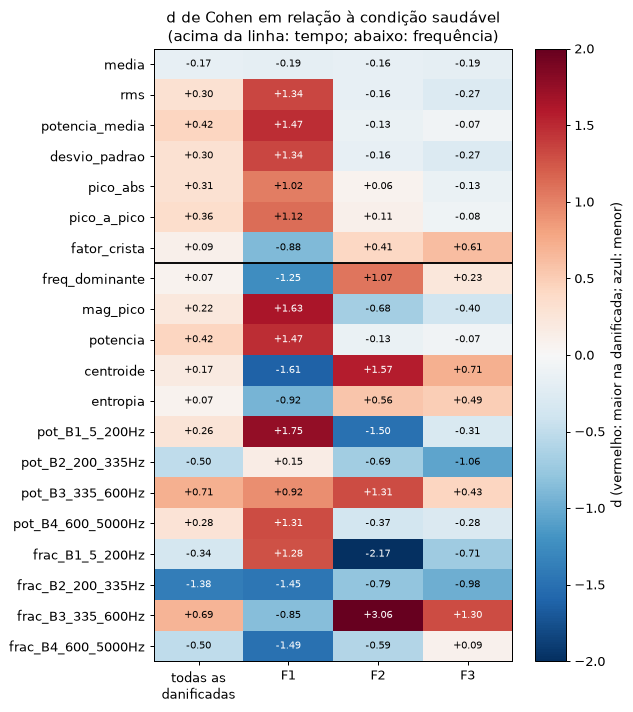

,todas,F1,F2,F3
media,-0.17,-0.19,-0.16,-0.19
rms,0.30,1.34,-0.16,-0.27
potencia_media,0.42,1.47,-0.13,-0.07
desvio_padrao,0.30,1.34,-0.16,-0.27
pico_abs,0.31,1.02,0.06,-0.13
pico_a_pico,0.36,1.12,0.11,-0.08
fator_crista,0.09,-0.88,0.41,0.61
freq_dominante,0.07,-1.25,1.07,0.23
mag_pico,0.22,1.63,-0.68,-0.40
potencia,0.42,1.47,-0.13,-0.07


In [2]:
# d de Cohen contra a condição saudável: todas as danificadas juntas e cada grupo de falha separado
saud = df_feat[df_feat.F == 'F0']
comparacoes = {'todas': df_feat[df_feat.F != 'F0'], 'F1': df_feat[df_feat.F == 'F1'],
               'F2': df_feat[df_feat.F == 'F2'], 'F3': df_feat[df_feat.F == 'F3']}
d_grupos = pd.DataFrame({nome: {c: cohen_d(saud[c], grupo[c]) for c in COLS_D}
                         for nome, grupo in comparacoes.items()})

fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(d_grupos.values, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(4), ['todas as\ndanificadas', 'F1', 'F2', 'F3'])
ax.set_yticks(range(len(COLS_D)), COLS_D)
for i in range(len(COLS_D)):
    for j in range(4):
        v = d_grupos.values[i, j]
        ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > 1.2 else 'black')
ax.axhline(len(FEAT_TEMPO) - 0.5, color='k', lw=1.5)          # separa tempo (acima) de frequência (abaixo)
ax.set_title('d de Cohen em relação à condição saudável\n(acima da linha: tempo; abaixo: frequência)')
plt.colorbar(im, label='d (vermelho: maior na danificada; azul: menor)')
plt.tight_layout(); plt.savefig('comp_d_grupos.pdf'); plt.show()
d_grupos.round(2)

**Leitura do mapa.** Cada grupo de falha altera o sinal de um jeito, e os efeitos têm sentidos opostos:

- **F1** aumenta a intensidade (RMS: d = +1,34; pico absoluto: +1,02) e concentra a potência nas baixas frequências (fração em B1: +1,28; centroide: −1,61).
- **F2** não muda a intensidade (RMS: d = −0,16), mas tem muito mais potência em 335–600 Hz (fração em B3: +3,06; fração em B1: −2,17; centroide: +1,57).
- **F3** se parece mais com F2: intensidade um pouco menor (RMS: −0,27) e fração em B3 maior (+1,30).

Somando os três grupos, os efeitos se cancelam; por isso o RMS tem d = 0,30 e o centroide, 0,17 na coluna "todas". **Nenhum domínio é superior em todos os casos:** as características de intensidade (tempo) destacam bem F1 e quase não distinguem F2 e F3; as de distribuição da potência (frequência) são as únicas que destacam F2 e F3, e também separam F1. A única característica com efeito de mesmo sentido nos três grupos é a fração em B2 (−1,45, −0,79 e −0,98; −1,38 no conjunto).

*Cuidado na leitura:* o d de Cohen descreve o tamanho da diferença entre as janelas. As 720 janelas vêm de apenas 12 registros (3 saudáveis), então ele não equivale a um teste estatístico com 720 observações independentes.

### **4.2 Redundância entre características**

Correlação do RMS com as frações por banda: {'frac_B1_5_200Hz': 0.4, 'frac_B2_200_335Hz': -0.39, 'frac_B3_335_600Hz': -0.31, 'frac_B4_600_5000Hz': -0.89}


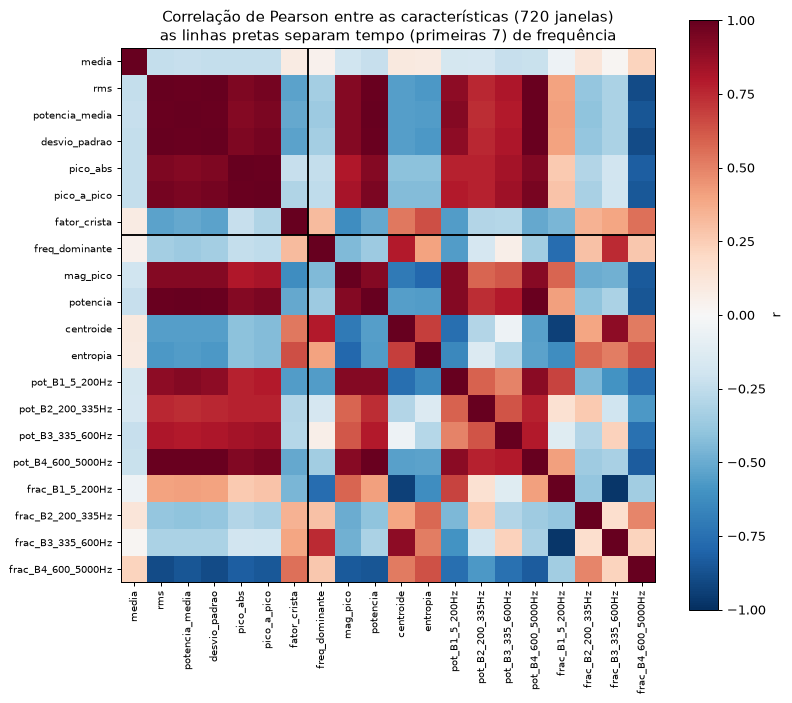

,característica 1,característica 2,r
1,rms,desvio_padrao,1.000
11,potencia_media,potencia,1.000
18,desvio_padrao,pot_B4_600_5000Hz,0.991
6,rms,pot_B4_600_5000Hz,0.991
19,pico_abs,pico_a_pico,0.991
28,potencia,pot_B4_600_5000Hz,0.990
13,potencia_media,pot_B4_600_5000Hz,0.990
5,rms,potencia,0.989
0,rms,potencia_media,0.989
17,desvio_padrao,potencia,0.989


In [3]:
corr_todas = df_feat[COLS_D].corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr_todas.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(COLS_D)), COLS_D, rotation=90, fontsize=8)
ax.set_yticks(range(len(COLS_D)), COLS_D, fontsize=8)
n_t = len(FEAT_TEMPO)
ax.axhline(n_t - 0.5, color='k', lw=1.5); ax.axvline(n_t - 0.5, color='k', lw=1.5)   # separa tempo de frequência
ax.set_title('Correlação de Pearson entre as características (720 janelas)\n'
             'as linhas pretas separam tempo (primeiras 7) de frequência')
plt.colorbar(im, label='r'); plt.tight_layout(); plt.savefig('comp_correlacao.pdf'); plt.show()

# pares praticamente redundantes (|r| >= 0,90)
pares = [(a, b, corr_todas.loc[a, b]) for i, a in enumerate(COLS_D) for b in COLS_D[i+1:]
         if abs(corr_todas.loc[a, b]) >= 0.90]
print('Correlação do RMS com as frações por banda:', corr_todas.loc['rms', FRAC_BANDAS].round(2).to_dict())
pd.DataFrame(pares, columns=['característica 1', 'característica 2', 'r']).sort_values('r', ascending=False).round(3)

**Leitura.** Existe um grande bloco de características que medem a mesma coisa, a **intensidade** da vibração. Desvio padrão, potência média, potência total do espectro, pico a pico, pico absoluto, magnitude do pico dominante e potência absoluta em B4 têm correlação muito alta com o RMS (r entre 0,92 e 1,00); a potência absoluta em B1 também acompanha o bloco (r = 0,89 com o RMS).

Duas dessas igualdades são esperadas pela teoria. RMS ≈ desvio padrão porque a média é ≈ 0 (seção 2.4). E a potência total do espectro coincide com a potência média no tempo (r = 1,00): pela relação de Parseval, a soma do espectro é igual à variância do sinal, que aqui equivale à potência média porque a média é ≈ 0. Ou seja, **a potência espectral total não acrescenta nada ao RMS**: é a mesma informação vista pelo outro domínio.

As potências absolutas por banda também acompanham a intensidade (r de 0,76 a 0,99 com o RMS). Já as **frações** em B1, B2 e B3 dependem pouco dela (|r| ≤ 0,40 com o RMS) e por isso são mais adequadas para descrever a forma do espectro. A exceção é a fração em B4 (r = −0,89 com o RMS): ela cai quando a vibração é forte, ou seja, também mede intensidade. Entre as frações, B1 e B3 são quase o espelho uma da outra (r = −0,97), e o centroide resume as duas (r = −0,94 com a fração em B1 e +0,90 com a fração em B3).

Trazem informação própria, com correlação apenas moderada com o RMS (|r| entre 0,39 e 0,58): o fator de crista, a entropia espectral e a fração da potência em B2.

### **4.3 Achado 1: mesma intensidade, espectros diferentes**

Para comparar os dois domínios nos mesmos registros, escolhemos duas janelas com praticamente o mesmo RMS, uma saudável e uma do grupo F2, e mostramos as duas no tempo e na frequência. O terceiro gráfico coloca as 720 janelas no plano RMS (tempo) × fração da potência em B3 (frequência).

Janelas com RMS entre 0.239 e 0.309 m/s² (do 1º ao 3º quartil das saudáveis):


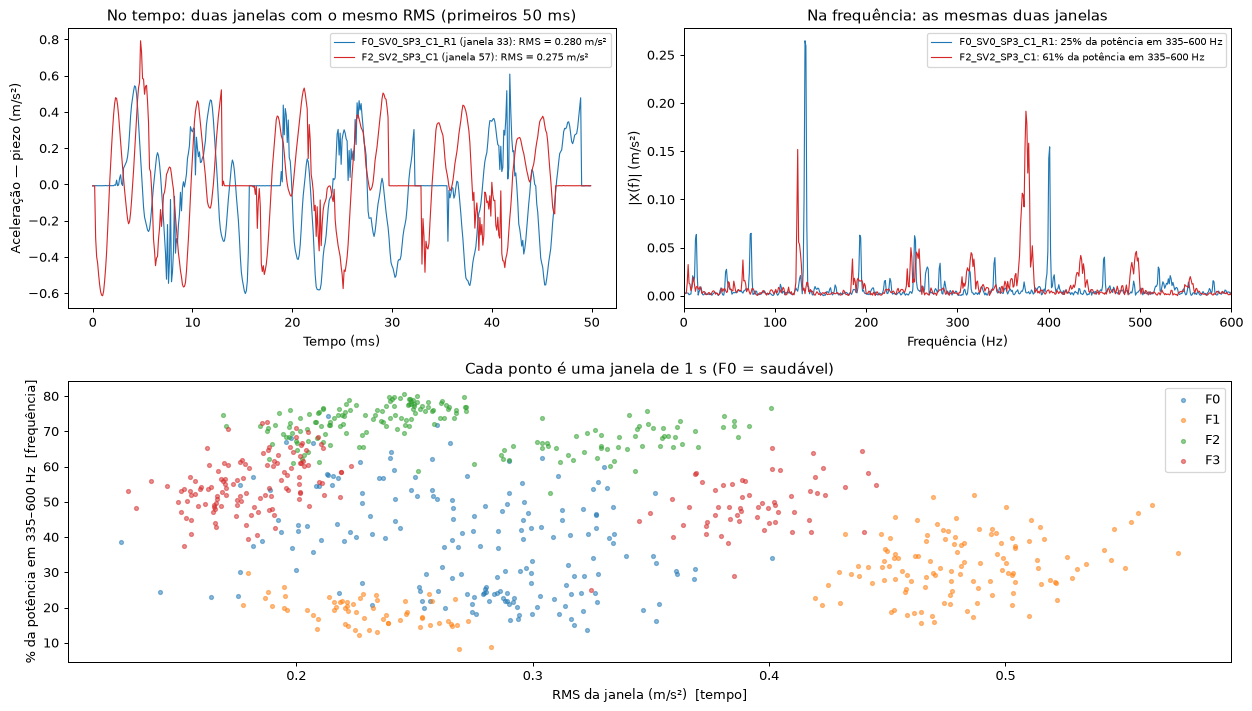

,n_janelas,rms_medio,frac_B3_media
F,,,
F0,90,0.277,0.361
F1,19,0.259,0.167
F2,65,0.262,0.737


In [4]:
# escolhe uma janela saudável com RMS típico e a janela do grupo F2 com o RMS mais próximo
rms_mediano = saud['rms'].median()
i_s = (saud['rms'] - rms_mediano).abs().idxmin()
f2 = df_feat[df_feat.F == 'F2']
i_d = (f2['rms'] - df_feat.loc[i_s, 'rms']).abs().idxmin()

fig = plt.figure(figsize=(14, 8))
ax0 = fig.add_subplot(2, 2, 1); ax1 = fig.add_subplot(2, 2, 2); ax2 = fig.add_subplot(2, 1, 2)
t_ms = np.arange(N) / FS * 1000
for i, cond in [(i_s, 'saudavel'), (i_d, 'danificada')]:
    r = df_feat.loc[i]
    ax0.plot(t_ms[:500], janelas[i][:500], lw=0.9, color=CORES[cond],
             label=f"{r['arquivo']} (janela {r['janela']}): RMS = {r['rms']:.3f} m/s²")
    ax1.plot(f_jan, espectros[i], lw=0.9, color=CORES[cond],
             label=f"{r['arquivo']}: {100 * r['frac_B3_335_600Hz']:.0f}% da potência em 335–600 Hz")
ax0.set_xlabel('Tempo (ms)'); ax0.set_ylabel('Aceleração — piezo (m/s²)'); ax0.legend(fontsize=8, loc='upper right')
ax0.set_title('No tempo: duas janelas com o mesmo RMS (primeiros 50 ms)')
ax1.set_xlim(0, 600); ax1.set_xlabel('Frequência (Hz)'); ax1.set_ylabel('|X(f)| (m/s²)'); ax1.legend(fontsize=8)
ax1.set_title('Na frequência: as mesmas duas janelas')
for f_cod in CORES_F:
    g = df_feat[df_feat.F == f_cod]
    ax2.scatter(g['rms'], 100 * g['frac_B3_335_600Hz'], s=10, alpha=0.5, color=CORES_F[f_cod], label=f_cod)
ax2.set_xlabel('RMS da janela (m/s²)  [tempo]'); ax2.set_ylabel('% da potência em 335–600 Hz  [frequência]')
ax2.set_title('Cada ponto é uma janela de 1 s (F0 = saudável)'); ax2.legend()
plt.tight_layout(); plt.savefig('comp_achado1.pdf'); plt.show()

# janelas com RMS na faixa central das saudáveis: quanto da potência está em B3, por grupo de falha?
q1, q3 = saud['rms'].quantile([0.25, 0.75])
mesma_faixa = df_feat[(df_feat['rms'] >= q1) & (df_feat['rms'] <= q3)]
print(f'Janelas com RMS entre {q1:.3f} e {q3:.3f} m/s² (do 1º ao 3º quartil das saudáveis):')
(mesma_faixa.groupby('F').agg(n_janelas=('rms', 'size'), rms_medio=('rms', 'mean'),
                              frac_B3_media=('frac_B3_335_600Hz', 'mean')).round(3))

**Achado 1.** Pelas medidas do tempo, as duas janelas são equivalentes: RMS de 0,280 e 0,275 m/s². Na frequência, elas são muito diferentes: na saudável domina o pico de ≈ 133 Hz, e só 25% da potência está entre 335 e 600 Hz; na danificada a maior componente é a de ≈ 375 Hz, e 61% da potência está nessa banda.

O gráfico de dispersão mostra que isso vale para o conjunto. Entre as janelas com RMS na metade central das saudáveis (do 1º ao 3º quartil: 0,24 a 0,31 m/s²), a fração média em B3 é 36% nas saudáveis, 17% em F1 e 74% em F2 (nenhuma janela de F3 cai nessa faixa). No eixo horizontal (RMS), dois registros de F1 se afastam claramente das saudáveis, para valores mais altos, e um de F3 se afasta em parte; no eixo vertical (fração em B3), quem mais se afasta é F2. **O tempo mede quanto o sinal vibra; a frequência mostra onde essa potência está.** Duas condições podem ter a mesma intensidade e espectros diferentes, e só a análise em frequência as distingue.

*Observação:* os trechos quase planos visíveis no gráfico temporal (≈ 3 ms a cada ≈ 16,7 ms) aparecem em todos os registros analisados, saudáveis e danificados, com a mesma periodicidade.

### **4.4 Achado 2: a posição dos picos acompanha a tensão da bateria**

Na seção 3, os picos principais da condição danificada aparecem em frequências um pouco menores (133 → 128 Hz). Essa diferença é invisível no tempo: corresponde a uma mudança de ≈ 0,3 ms no período da oscilação (7,5 → 7,8 ms). Antes de atribuí-la ao defeito, verificamos uma condição de operação que os próprios arquivos registram: a tensão da bateria (`BatteryVolt`).

Medimos, em cada janela, a frequência do maior pico entre 100 e 160 Hz e comparamos a média de cada registro com a tensão média da bateria. Como verificação auxiliar, incluímos os 9 registros danificados de SP3/C2: são os mesmos grupos de falha e severidades, registrados com outra tensão da bateria. Eles são usados **somente** nesta verificação.

Um ponto por registro (SP3/C1):
         arquivo  bateria_V  f_pico   rms  frac_B3
F0_SV0_SP3_C1_R1     15.417 133.567 0.294    0.228
F0_SV0_SP3_C1_R2     15.445 132.833 0.217    0.478
F0_SV0_SP3_C1_R3     15.547 133.617 0.307    0.434
   F1_SV1_SP3_C1     14.970 130.133 0.230    0.186
   F1_SV2_SP3_C1     14.716 128.867 0.477    0.258
   F1_SV3_SP3_C1     14.522 127.333 0.488    0.382
   F2_SV1_SP3_C1     14.392 125.950 0.248    0.760
   F2_SV2_SP3_C1     14.320 125.133 0.335    0.671
   F2_SV3_SP3_C1     14.501 126.633 0.209    0.709
   F3_SV1_SP3_C1     15.065 130.350 0.165    0.509
   F3_SV2_SP3_C1     15.320 132.850 0.393    0.492
   F3_SV3_SP3_C1     14.686 127.800 0.195    0.594

Correlação com a tensão da bateria, um ponto por registro (21 registros):
f_pico     1.00
rms       -0.11
frac_B3   -0.59


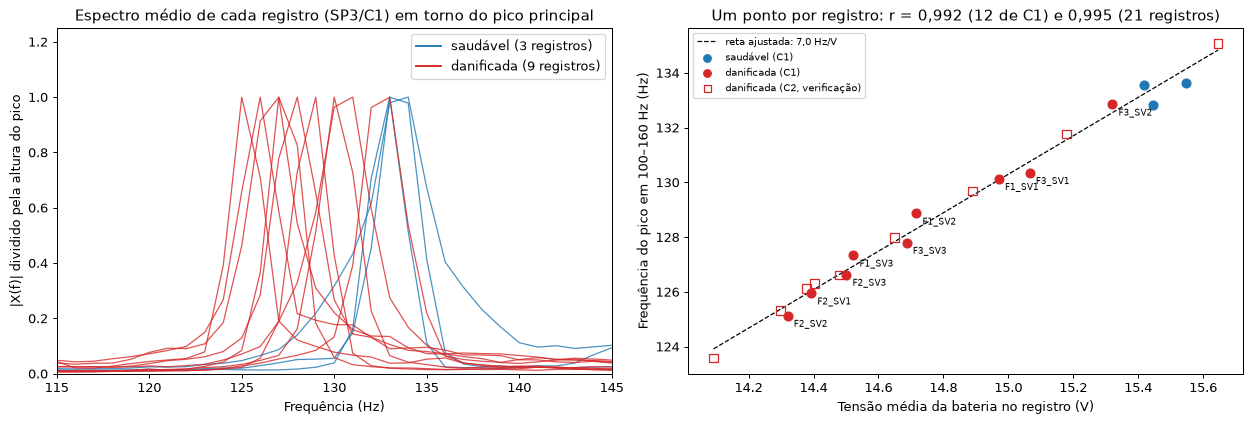

bateria_V         f_pico        
C             C1     C2      C1      C2
falha                                  
F1_SV1     14.97  15.65  130.13  135.07
F1_SV2     14.72  15.18  128.87  131.77
F1_SV3     14.52  14.89  127.33  129.68
F2_SV1     14.39  14.65  125.95  128.00
F2_SV2     14.32  14.48  125.13  126.62
F2_SV3     14.50  14.38  126.63  126.13
F3_SV1     15.07  14.30  130.35  125.33
F3_SV2     15.32  14.09  132.85  123.58
F3_SV3     14.69  14.40  127.80  126.30

In [5]:
# frequência do maior pico entre 100 e 160 Hz em cada janela
# (busca restrita a essa faixa para não alternar com o pico de ~400 Hz, como acontece com a frequência dominante)
faixa = (f_jan >= 100) & (f_jan <= 160)
df_feat['f_pico_100_160'] = f_jan[faixa][espectros[:, faixa].argmax(axis=1)]

# um ponto por registro. BatteryVolt usa a base de tempo da IMU (não sincronizada com o piezo),
# por isso comparamos a média do registro, e não janela a janela.
reg = (df_feat.groupby(['arquivo', 'condicao', 'F'])
       .agg(f_pico=('f_pico_100_160', 'mean'), rms=('rms', 'mean'), frac_B3=('frac_B3_335_600Hz', 'mean')).reset_index())
reg['bateria_V'] = [np.mean(loadmat(c, squeeze_me=True)['BatteryVolt'])
                    for c in sel.set_index('arquivo').loc[reg['arquivo'], 'caminho']]
reg['C'] = 'C1'

# verificação auxiliar: mesmos grupos de falha e severidades em SP3/C2 (usados somente aqui)
linhas_c2 = []
for _, r in tabela[(tabela['SP'] == 'SP3') & (tabela['C'] == 'C2') & (tabela['F'] != 'F0')].iterrows():
    d = loadmat(r['caminho'], squeeze_me=True, struct_as_record=False)
    x = d['AccData'].Vib_Data
    jan = [x[k*N:(k+1)*N] for k in range(len(x) // N)]
    cf = pd.DataFrame([caracteristicas_freq(w, FS) for w in jan])
    linhas_c2.append({'arquivo': r['arquivo'], 'condicao': 'danificada', 'F': r['F'],
                      'f_pico': np.mean([f_jan[faixa][espectro(w, FS)[1][faixa].argmax()] for w in jan]),
                      'rms': np.mean([np.sqrt(np.mean(w**2)) for w in jan]),
                      'frac_B3': (cf['pot_B3_335_600Hz'] / cf['potencia']).mean(),
                      'bateria_V': np.mean(d['BatteryVolt']), 'C': 'C2'})
reg_todos = pd.concat([reg, pd.DataFrame(linhas_c2)], ignore_index=True)

r_c1 = reg['bateria_V'].corr(reg['f_pico'])
r_todos = reg_todos['bateria_V'].corr(reg_todos['f_pico'])
a, b = np.polyfit(reg_todos['bateria_V'], reg_todos['f_pico'], 1)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
for _, r in reg.iterrows():
    media = espectros[(df_janelas['arquivo'] == r['arquivo']).values].mean(axis=0)
    axs[0].plot(f_jan, media / media[faixa].max(), lw=1, color=CORES[r['condicao']], alpha=0.8)
axs[0].plot([], [], color=CORES['saudavel'], label='saudável (3 registros)')
axs[0].plot([], [], color=CORES['danificada'], label='danificada (9 registros)')
axs[0].set_xlim(115, 145); axs[0].set_ylim(0, 1.25); axs[0].legend(loc='upper right')
axs[0].set_xlabel('Frequência (Hz)'); axs[0].set_ylabel('|X(f)| dividido pela altura do pico')
axs[0].set_title('Espectro médio de cada registro (SP3/C1) em torno do pico principal')

for _, r in reg_todos.iterrows():
    cheio = r['C'] == 'C1'
    axs[1].scatter(r['bateria_V'], r['f_pico'], s=50, marker='o' if cheio else 's', zorder=3,
                   facecolors=CORES[r['condicao']] if cheio else 'none', edgecolors=CORES[r['condicao']])
    if cheio and r['F'] != 'F0':
        axs[1].annotate(r['arquivo'].replace('_SP3_C1', ''), (r['bateria_V'], r['f_pico']), fontsize=7,
                        xytext=(5, -9), textcoords='offset points')
xv = np.array([reg_todos['bateria_V'].min(), reg_todos['bateria_V'].max()])
axs[1].plot(xv, a * xv + b, 'k--', lw=1, label=f'reta ajustada: {a:.1f} Hz/V'.replace('.', ','))
axs[1].scatter([], [], marker='o', color=CORES['saudavel'], label='saudável (C1)')
axs[1].scatter([], [], marker='o', color=CORES['danificada'], label='danificada (C1)')
axs[1].scatter([], [], marker='s', facecolors='none', edgecolors=CORES['danificada'], label='danificada (C2, verificação)')
axs[1].set_xlabel('Tensão média da bateria no registro (V)'); axs[1].set_ylabel('Frequência do pico em 100–160 Hz (Hz)')
axs[1].set_title(f'Um ponto por registro: r = {r_c1:.3f} (12 de C1) e {r_todos:.3f} (21 registros)'.replace('.', ',')); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig('comp_achado2.pdf'); plt.show()

print('Um ponto por registro (SP3/C1):')
print(reg[['arquivo', 'bateria_V', 'f_pico', 'rms', 'frac_B3']].round(3).to_string(index=False))
print('\nCorrelação com a tensão da bateria, um ponto por registro (21 registros):')
print(reg_todos[['f_pico', 'rms', 'frac_B3']].corrwith(reg_todos['bateria_V']).round(2).to_string())

# o mesmo grupo de falha e severidade, em C1 e em C2
reg_todos['falha'] = reg_todos['arquivo'].str[:6]
(reg_todos[reg_todos['F'] != 'F0'].pivot(index='falha', columns='C', values=['bateria_V', 'f_pico']).round(2))

**Achado 2.** A frequência do pico acompanha a tensão da bateria quase perfeitamente: r = 0,992 nos 12 registros de C1 e r = 0,995 nos 21 registros (≈ 7 Hz por volt).

- Os três registros saudáveis foram gravados com a bateria mais carregada (15,4 a 15,5 V) e têm o pico em ≈ 133 Hz. Os danificados foram gravados com 14,3 a 15,3 V e têm o pico entre 125 e 133 Hz.
- O registro danificado gravado com tensão próxima à dos saudáveis (F3_SV2, 15,3 V) tem o pico no mesmo lugar que eles (132,9 Hz).
- O mesmo grupo de falha e severidade, com tensões diferentes, tem o pico em lugares diferentes: F1_SV1 está em 130,1 Hz com 14,97 V (C1) e em 135,1 Hz com 15,65 V (C2), acima dos saudáveis.
- O pico próximo de 400 Hz visto na seção 3 acompanha esse deslocamento (≈ 380 contra ≈ 400 Hz), ficando perto do triplo da frequência do primeiro.

Portanto, **o deslocamento dos picos entre as condições acompanha a diferença de tensão da bateria entre os registros e, com estes dados, não pode ser atribuído ao defeito.** O padrão é compatível com uma variação da velocidade de rotação dos motores com a tensão, mas o dataset não informa a rotação; por isso não afirmamos essa causa.

Este é um caso em que a frequência revela algo que o tempo não mostra e, ao mesmo tempo, um aviso: uma característica espectral pode separar as condições por um motivo que não é o defeito. Nos 21 registros, a fração da potência em B3 também tem relação com a tensão da bateria (r ≈ −0,6, um ponto por registro), bem mais fraca que a do pico. Por isso tratamos a tensão da bateria como **variável de confusão**: um risco a considerar na interpretação, não uma conclusão. O RMS não tem essa relação (r ≈ −0,1).

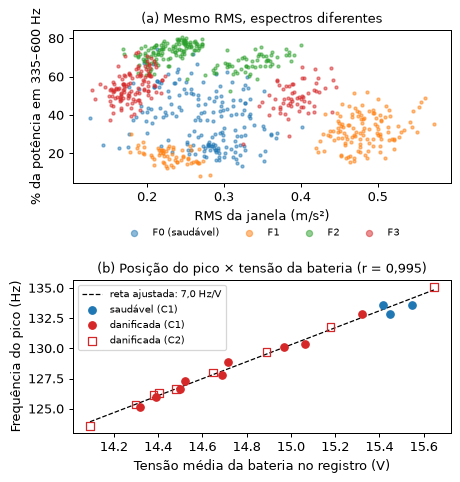

In [6]:
# figura-resumo para o relatório: os dois achados, um sobre o outro (largura de uma coluna)
fig, axs = plt.subplots(2, 1, figsize=(5.2, 5.4))
for f_cod in CORES_F:
    g = df_feat[df_feat.F == f_cod]
    axs[0].scatter(g['rms'], 100 * g['frac_B3_335_600Hz'], s=6, alpha=0.5, color=CORES_F[f_cod],
                   label='F0 (saudável)' if f_cod == 'F0' else f_cod)
axs[0].set_xlabel('RMS da janela (m/s²)'); axs[0].set_ylabel('% da potência em 335–600 Hz')
axs[0].set_title('(a) Mesmo RMS, espectros diferentes', fontsize=10)
axs[0].legend(fontsize=8, markerscale=2, ncol=4, loc='lower center', bbox_to_anchor=(0.5, -0.42), frameon=False)
for _, r in reg_todos.iterrows():
    cheio = r['C'] == 'C1'
    axs[1].scatter(r['bateria_V'], r['f_pico'], s=35, marker='o' if cheio else 's', zorder=3,
                   facecolors=CORES[r['condicao']] if cheio else 'none', edgecolors=CORES[r['condicao']])
axs[1].plot(xv, a * xv + b, 'k--', lw=1, label=f'reta ajustada: {a:.1f} Hz/V'.replace('.', ','))
axs[1].scatter([], [], marker='o', color=CORES['saudavel'], label='saudável (C1)')
axs[1].scatter([], [], marker='o', color=CORES['danificada'], label='danificada (C1)')
axs[1].scatter([], [], marker='s', facecolors='none', edgecolors=CORES['danificada'], label='danificada (C2)')
axs[1].set_xlabel('Tensão média da bateria no registro (V)'); axs[1].set_ylabel('Frequência do pico (Hz)')
axs[1].set_title(f'(b) Posição do pico × tensão da bateria (r = {r_todos:.3f})'.replace('.', ','), fontsize=10); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig('09_notebook_comparacao.png', dpi=200); plt.show()

### **4.5 Características mais úteis e conjunto para a classificação**

**Quais características de cada domínio são mais úteis para separar as condições?**

- **Tempo:** o RMS, que resume o bloco de intensidade e destaca bem F1 (d = +1,34), e o fator de crista, a única característica temporal que muda em F2 e F3 (d = +0,41 e +0,61) e que tem correlação apenas moderada com o RMS (r = −0,53).
- **Frequência:** as frações da potência em B2 e B3 e a entropia espectral. Elas destacam F2 e F3, os grupos que o RMS não separa, e também F1. A potência total do espectro fica fora porque repete o RMS (seção 4.2): assim o modelo espectral avalia só a *forma* do espectro. B2 e B3 são bandas largas, e o deslocamento dos picos com a tensão da bateria (≈ 10 Hz no primeiro pico) não atravessa os limites delas; ainda assim, o risco de confusão na fração em B3 (seção 4.4) será acompanhado na 2ª entrega.
- **Nenhum domínio é suficiente sozinho:** o tempo (RMS) destaca bem F1, mas quase não distingue F2 e F3; a frequência destaca os três grupos pela forma do espectro, mas varia mais entre as repetições saudáveis e carrega o risco de confusão com a tensão da bateria. A expectativa para a 2ª entrega é que o modelo combinado (C) aproveite as duas informações, o que será verificado com a divisão de treino e teste por registro.

**Conjunto proposto para a classificação (2ª entrega):**

| Modelo | Características |
|---|---|
| A (tempo) | RMS, fator de crista |
| B (frequência) | fração da potência em B2, fração da potência em B3, entropia espectral |
| C (combinado) | as cinco acima |

**O que ficou de fora e por quê** (todas continuam extraídas, apresentadas e analisadas nas seções 2 e 3):

- desvio padrão, potência média, potência total do espectro, pico a pico, pico absoluto e magnitude do pico dominante: redundantes com o RMS (r ≥ 0,92); além disso, pico absoluto = RMS × fator de crista;
- potências absolutas por banda: acompanham a intensidade; foram substituídas pelas frações;
- fração em B1 e centroide: redundantes com a fração em B3 (r = −0,97 e ≈ +0,90); fração em B4: menos de 5% da potência e ligada ao RMS (r = −0,89);
- média: ≈ 0 e não separa as condições (|d| < 0,2);
- frequência dominante: alterna entre ≈ 133 e ≈ 400 Hz de uma janela para outra (seção 3) e sua posição acompanha a tensão da bateria (achado 2);
- frequência do pico em 100–160 Hz: separaria bem as janelas, mas pelo motivo errado (a tensão da bateria). Fica apenas como ferramenta de interpretação.

**Limitações.** (i) As 720 janelas vêm de 12 registros, e só 3 são saudáveis; os registros saudáveis diferem entre si (fração em B3 de 23% em R1, contra 48% em R2 e 43% em R3; tabela da seção 4.4), em grau parecido com a diferença entre condições. (ii) A tensão da bateria difere sistematicamente entre saudáveis e danificados e é uma variável de confusão para as características espectrais. (iii) O significado do código C não é documentado. Por isso, os resultados valem para este recorte (SP3/C1) e a separação observada entre janelas não deve ser lida como capacidade de detectar o defeito em novos ensaios.